# Day 6 · Information Value for Every Feature & an Out-of-Time Split

*Work log: a cleaned version of my working notebook. The polished analysis lives in [`../06_feature_selection_and_split`](../06_feature_selection_and_split.ipynb).*

**Goals:** screen features for availability, write a reusable IV function, rank all application-time features, catch a leaky feature, and set up development / out-of-time samples.

**Key results:** FICO is the only medium-strength feature (IV 0.135). Binning inquiries by count raised their IV from 0.028 to 0.043. `last_fico_range_high` has IV 3.63 (a leak). The development sample covers Jan-2014 to Jun-2015 (64%) and the out-of-time sample Jul–Dec 2015 (36%).

## 1. Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = (Path.cwd().parents[1] / "Data").resolve()   # project_root/Data
con = duckdb.connect()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
import numpy as np

In [2]:
# Rebuild the analysis views (DuckDB views are in-memory and reset every session)

# loans: every accepted loan
con.sql(f"""
CREATE OR REPLACE VIEW loans AS
SELECT *
FROM '{DATA}/accepted.parquet'
""")

# loans_clean: drop the 33 file-footer rows and parse the text issue date ('Dec-2015') into a real date
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *,
       strptime(issue_d, '%b-%Y') AS issue_date
FROM loans
WHERE loan_status IS NOT NULL
""")

# cohort: 36-month loans issued 2014-2015, all matured by Dec-2018 so outcomes are final
con.sql("""
CREATE OR REPLACE VIEW cohort AS
SELECT *
FROM loans_clean
WHERE issue_date BETWEEN '2014-01-01' AND '2015-12-31'
  AND TRIM(term) = '36 months'
""")

# rejected: declined applications
con.sql(f"""
CREATE OR REPLACE VIEW rejected AS
SELECT *
FROM '{DATA}/rejected.parquet'
""")

con.sql("SHOW TABLES").df()

,name
0,cohort
1,loans
2,loans_clean
3,rejected


## 2. Availability screen (no code)
* **Usable** (known at application): FICO, income, DTI, revolving utilization, inquiries, past delinquencies, employment length, purpose, home ownership, verification status.
* **Leaks** (exist only after the loan is issued): `total_pymnt`, `recoveries`, `last_fico_range_high`, `last_pymnt_d`.
* **Existing model output** (benchmark only): `grade`, `int_rate`, and `installment`, which is computed from the rate.

What counts as usable depends on the **decision point**: for a post-origination early-warning model, `int_rate` would be fine.

## 3. My first function: `calc_iv`
The Day 5 IV steps, wrapped in a function so they can be reused for any binned column.

In [3]:
def calc_iv(df, bin_col):
    # per bin: bads = sum of the 0/1 flag; total = count of non-NULL flags (indeterminate loans excluded)
    t = df.groupby(bin_col, observed=True, dropna=False)["bad_flag"].agg(n_bad="sum", n_total="count")
    t["n_good"] = t["n_total"] - t["n_bad"]

    # distributions across bins, WOE and each bin's IV contribution
    t["dist_good"] = t["n_good"] / t["n_good"].sum()
    t["dist_bad"]  = t["n_bad"] / t["n_bad"].sum()
    t["woe"]       = np.log(t["dist_good"] / t["dist_bad"])
    t["iv_bin"]    = (t["dist_good"] - t["dist_bad"]) * t["woe"]

    return t, t["iv_bin"].sum()

In [4]:
# Test against a known answer: income IV was 0.0615 on Day 5
df = con.sql("""
SELECT CASE WHEN annual_inc < 40000  THEN '1. <40k'
            WHEN annual_inc < 60000  THEN '2. 40-60k'
            WHEN annual_inc < 80000  THEN '3. 60-80k'
            WHEN annual_inc < 100000 THEN '4. 80-100k'
            ELSE '5. 100k+' END AS income_band,
       CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag
FROM cohort
""").df()

table, iv = calc_iv(df, "income_band")
print(iv)
table

0.06153955544225563


,n_bad,n_total,n_good,dist_good,dist_bad,woe,iv_bin
income_band,,,,,,,
1. <40k,16293,83088,66795,0.175246,0.252573,-0.365508,0.028264
2. 40-60k,18887,120972,102085,0.267835,0.292785,-0.089069,0.002222
3. 60-80k,13387,96871,83484,0.219032,0.207525,0.05397,0.000621
4. 80-100k,7077,58943,51866,0.136078,0.109707,0.215412,0.005681
5. 100k+,8864,85783,76919,0.201808,0.137409,0.384354,0.024752


## 4. Numeric features: automatic binning with `pd.qcut`
`qcut` splits by quantiles (equal-sized bins). Count variables concentrated at zero collapse to 2 quantile bins, so they are binned by value with `.clip(upper=3)` (0 / 1 / 2 / 3+).

In [5]:
num = con.sql("""
SELECT CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag,
       fico_range_low, annual_inc, dti, revol_util, inq_last_6mths, delinq_2yrs, loan_amnt
FROM cohort
""").df()

results = []
for col in ["fico_range_low", "annual_inc", "revol_util", "inq_last_6mths", "delinq_2yrs", "loan_amnt", "dti"]:
    if col in ["inq_last_6mths", "delinq_2yrs"]:
        num["bin"] = num[col].clip(upper=3)                      # bin by count
    else:
        num["bin"] = pd.qcut(num[col], q=5, duplicates="drop")   # quantile bins
    table, iv = calc_iv(num, "bin")
    results.append({"variable": col, "iv": iv, "n_bins": len(table)})

ranking = pd.DataFrame(results).sort_values("iv", ascending=False)
ranking

,variable,iv,n_bins
0,fico_range_low,0.134928,5
1,annual_inc,0.061869,5
6,dti,0.053966,6
3,inq_last_6mths,0.043128,4
2,revol_util,0.012954,6
5,loan_amnt,0.004995,5
4,delinq_2yrs,0.002497,4


**Lessons**
* A low IV can mean a weak variable **or** an unsuitable binning: with `qcut`, inquiries had 2 bins and IV 0.028; by count, 4 bins and 0.043. Past delinquencies stay weak either way.
* IV is not a fixed property of a variable: it depends on the bins (income: 0.0615 with hand-picked bins, 0.0619 with quantiles).
* **Bug I fixed:** the IV and append lines were indented under `else`, so the count-binned variables silently disappeared from the results.

## 5. Categorical features

In [6]:
cat = con.sql("""
SELECT CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag,
       purpose, home_ownership, emp_length, verification_status
FROM cohort
""").df()

results_cat = []
for col in ["purpose", "home_ownership", "emp_length", "verification_status"]:
    table, iv = calc_iv(cat, col)
    results_cat.append({"variable": col, "iv": iv, "n_bins": len(table)})

pd.DataFrame(results_cat).sort_values("iv", ascending=False)

,variable,iv,n_bins
0,purpose,inf,14
1,home_ownership,inf,4
3,verification_status,0.040072,3
2,emp_length,0.021491,12


`purpose` and `home_ownership` return **inf**: `wedding` (11 loans), `educational` (1) and `ANY` (2) have **zero bads**, so `dist_bad = 0` and WOE = ln(x / 0) = ∞. Tiny categories must be merged into an **existing** large category (a new tiny `OTHER` group would still have zero bads).

In [7]:
# Merge purposes with fewer than 300 loans into the existing 'other' category
counts = cat["purpose"].value_counts()
small = counts[counts < 300].index
cat["purpose_grp"] = cat["purpose"].where(~cat["purpose"].isin(small), "other")

# ANY (2 loans): merged into RENT, the conservative (riskiest) choice; MORTGAGE gives the same IV
cat["home_grp"] = cat["home_ownership"].replace("ANY", "RENT")

results_cat = []
for col in ["purpose_grp", "home_grp", "emp_length", "verification_status"]:
    table, iv = calc_iv(cat, col)
    results_cat.append({"variable": col, "iv": iv, "n_bins": len(table)})

cat_ranking = pd.DataFrame(results_cat).sort_values("iv", ascending=False)
final = pd.concat([ranking, cat_ranking]).sort_values("iv", ascending=False)
final

,variable,iv,n_bins
0,fico_range_low,0.134928,5
1,annual_inc,0.061869,5
6,dti,0.053966,6
1,home_grp,0.043946,3
3,inq_last_6mths,0.043128,4
3,verification_status,0.040072,3
0,purpose_grp,0.021679,11
2,emp_length,0.021491,12
2,revol_util,0.012954,6
5,loan_amnt,0.004995,5


## 6. Benchmark and leakage check

In [8]:
check = con.sql("""
SELECT grade, int_rate, last_fico_range_high,
       CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END AS bad_flag
FROM cohort
""").df()

check_result = []
for col in ["grade", "int_rate", "last_fico_range_high"]:
    if col == "grade":
        check["bin"] = check[col]                                     # already categorical
    else:
        check["bin"] = pd.qcut(check[col], q=5, duplicates="drop")
    table, iv = calc_iv(check, "bin")
    check_result.append({"variable": col, "iv": iv, "n_bins": len(table)})

print(pd.DataFrame(check_result).sort_values("iv", ascending=False))

# `table` now holds the last feature: last_fico_range_high
table["bad_rate"] = table["n_bad"] / table["n_total"]
table

               variable        iv  n_bins
2  last_fico_range_high  3.631705       5
0                 grade  0.363543       7
1              int_rate  0.350812       5


,n_bad,n_total,n_good,dist_good,dist_bad,woe,iv_bin,bad_rate
bin,,,,,,,,
"(-0.001, 609.0]",50829,89191,38362,0.100648,0.787949,-2.057801,1.414327,0.569889
"(609.0, 674.0]",11600,89217,77617,0.20364,0.179823,0.12438,0.002962,0.13002
"(674.0, 709.0]",1392,95263,93871,0.246284,0.021579,2.434779,0.547108,0.014612
"(709.0, 744.0]",444,83370,82926,0.217568,0.006883,3.453478,0.727598,0.005326
"(744.0, 850.0]",243,88616,88373,0.231859,0.003767,4.119859,0.939709,0.002742


* `grade` (0.36) and `int_rate` (0.35) are **strong**: they already combine many inputs. They are the benchmark, not inputs.
* `last_fico_range_high` has IV **3.63**: the lowest bin (< 609) has a 57% bad rate, even though every borrower had FICO ≥ 660 at application. Scores fell **after** default (reverse causality). It would look near-perfect in testing and fail in production.

## 7. IV ranking chart

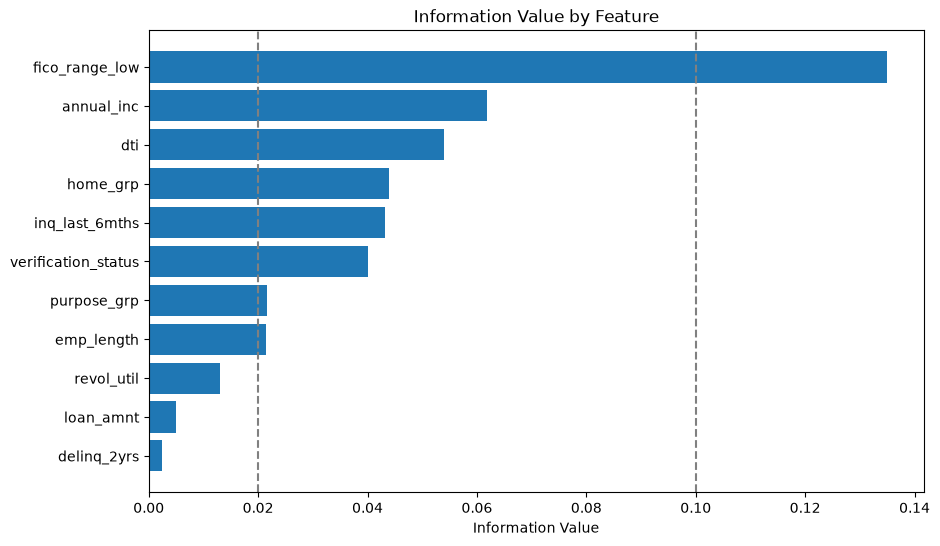

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
plot_df = final.sort_values("iv")                       # ascending, so the strongest bar ends up on top
ax.barh(plot_df["variable"], plot_df["iv"])
ax.axvline(0.02, linestyle="--", color="gray")          # below: useless
ax.axvline(0.1, linestyle="--", color="gray")           # weak | medium
ax.set_title("Information Value by Feature")
ax.set_xlabel("Information Value")
plt.show()

## 8. Development vs. out-of-time sample
Train on the past, test on the future. A random split would hide changes over time.

In [10]:
split_summary = con.sql("""
SELECT CASE WHEN issue_date < '2015-07-01' THEN 'development' ELSE 'oot' END AS sample,
       COUNT(*)                                          AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)  AS pct_loans,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
            WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate
FROM cohort
GROUP BY sample
ORDER BY sample
""").df()
split_summary

,sample,n_loans,pct_loans,bad_rate
0,development,283361,0.6357,0.1432
1,oot,162382,0.3643,0.1474


**Findings**
* My first split (2014 train vs. 2015 test) made the test sample larger than the training sample (64% vs. 36%) and showed a 1.2 pp bad-rate gap.
* In 2015 the grade mix **improved**, yet bad rates rose **within** almost every grade (F: 29.5% → 42.5%): **population drift**. A model trained only on 2014 would underestimate 2015 defaults.
* Final split: development Jan-2014 to Jun-2015 (64%, later 80/20 train/validation, about 51% / 13% overall) and out-of-time Jul–Dec 2015 (36%). The bad-rate gap shrinks to 0.4 pp.